# Tugas Praktikum - Multiple Linear Regression

**Nama:** Radit Firansah  
**NIM:** 244107020196

Multiple Linear Regression pada dataset Medical Cost Personal (insurance.csv).

## Deskripsi Dataset

Dataset **Medical Cost Personal** (`insurance.csv`) berisi 1338 baris data peserta asuransi
kesehatan di Amerika Serikat. Tujuannya memprediksi **biaya medis** (`charges`) dari
karakteristik peserta.

Variabel:

| Kolom | Tipe | Keterangan |
|-------|------|------------|
| `age` | numerik | Umur peserta |
| `sex` | kategori | Jenis kelamin (`female`/`male`) |
| `bmi` | numerik | Indeks massa tubuh |
| `children` | numerik | Jumlah anak/tanggungan |
| `smoker` | kategori | Status merokok (`yes`/`no`) |
| `region` | kategori | Wilayah tempat tinggal |
| `charges` | numerik | **Target**: biaya medis tahunan |

## 1. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## 2. Baca Dataset dan Lihat Isinya

In [2]:
data = pd.read_csv('../data/insurance.csv')
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
data.shape

(1338, 7)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
# cek apakah ada data kosong
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

## 3. Encoding Kolom Kategori
Kolom `sex`, `smoker`, dan `region` masih berupa teks, jadi harus diubah menjadi angka
menggunakan `pd.get_dummies`. Parameter `drop_first=True` dipakai untuk membuang satu
kolom agar tidak terjadi multikolinearitas.

In [7]:
data = pd.get_dummies(data, columns=['sex', 'smoker', 'region'], drop_first=True)
data.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


## 4. Tentukan Fitur (X) dan Target (y)
`charges` adalah target, sisanya menjadi fitur.

In [8]:
X = data.drop('charges', axis=1)
y = data['charges']

## 5. Bagi Data Train dan Test
Data dibagi 80% untuk latih dan 20% untuk uji.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 6. Feature Scaling
StandardScaler dipakai agar semua fitur punya skala yang sebanding.

In [10]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 7. Latih Model Multiple Linear Regression

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [12]:
# lihat koefisien tiap fitur
print('Intercept:', model.intercept_)
print('Koefisien:')
for nama, koef in zip(X.columns, model.coef_):
    print(nama, '=', koef)

Intercept: 13346.089736364485
Koefisien:
age = 3614.9754148279967
bmi = 2036.2281228967136
children = 516.8902471991562
sex_male = -9.29310107440194
smoker_yes = 9558.481408916747
region_northwest = -158.14098121114787
region_southeast = -290.15704747205615
region_southwest = -349.1106782088573


## 8. Prediksi pada Data Uji

In [13]:
y_pred = model.predict(X_test)

## 9. Evaluasi Model

In [14]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print('R-squared:', r2)
print('MSE:', mse)
print('MAE:', mae)

R-squared: 0.7835929767120722
MSE: 33596915.851361476
MAE: 4181.1944737536505


## 10. Visualisasi Actual vs Predicted
Semakin dekat titik ke garis merah, semakin akurat prediksi model.

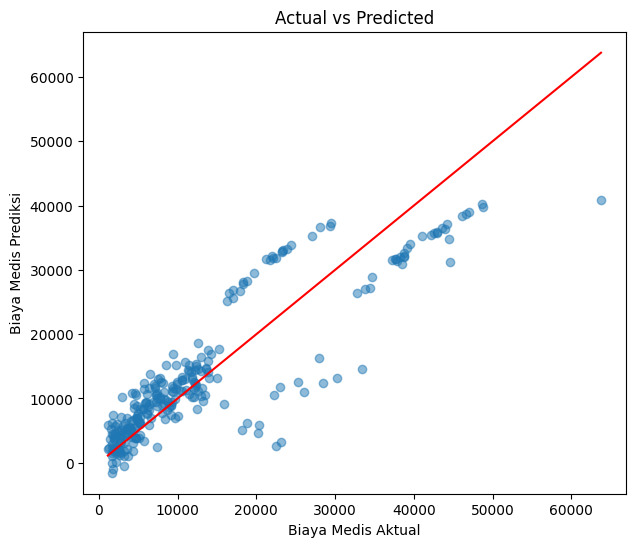

In [15]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r')
plt.xlabel('Biaya Medis Aktual')
plt.ylabel('Biaya Medis Prediksi')
plt.title('Actual vs Predicted')
plt.show()

## Analisis dan Kesimpulan

- Model multiple linear regression berhasil memprediksi biaya medis dengan nilai
  **R-squared sekitar 0.78**, artinya sekitar 78% variasi biaya medis dapat dijelaskan
  oleh fitur-fitur yang digunakan.
- Dari koefisien model, faktor **`smoker_yes`** dan **`age`** memberi pengaruh paling besar
  terhadap kenaikan biaya medis. Peserta yang merokok cenderung memiliki biaya jauh lebih tinggi.
- Nilai MAE dan MSE menunjukkan rata-rata kesalahan prediksi dalam satuan dolar. Selisihnya
  masih wajar, tetapi model belum sempurna karena hubungan antara fitur dan biaya medis
  tidak sepenuhnya linier (misalnya pengaruh BMI yang berbeda antara perokok dan bukan perokok).
- Pada scatter plot actual vs predicted, titik-titik mengikuti garis diagonal dengan cukup baik,
  walau ada beberapa titik dengan biaya sangat tinggi yang cenderung under-estimate.

**Kesimpulan:** multiple linear regression sudah cukup baik sebagai model dasar untuk
memprediksi biaya medis, dengan status merokok sebagai faktor paling dominan.